# Biodiversity-loss evidence differs across geographies

In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
for candidate in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
    if (candidate / "data_helpers").is_dir() and (candidate / "checklists").is_dir():
        PROJECT_ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the biodiversity repository root.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

In [3]:
from data_helpers import results_config, visualization
from data_helpers.analysis import driver_composition
from data_helpers.analysis.geo.geography import SHAPEFILE_PATH, load_polygons
from data_helpers.prep import evidence_corpus_prep

In [4]:
visualization.apply_style()

RESULTS_CONFIG = results_config.load_results_config()
DRIVER_CONFIG = RESULTS_CONFIG["driver_composition"]
EVIDENCE_CONFIG = RESULTS_CONFIG["biodiversity_evidence_prep"]
INCOME_CONFIG = RESULTS_CONFIG["world_bank_income"]
THREAT_ORDER, THREAT_COLORS, THREAT_DISPLAY_NAMES = results_config.threat_l0_display(
    RESULTS_CONFIG
)

INCOME_GROUPS = INCOME_CONFIG["group_order"]

MAPPING_PATH = PROJECT_ROOT / INCOME_CONFIG["world_bank_mapping"]
HISTORICAL_PATH = (
    PROJECT_ROOT
    / INCOME_CONFIG["world_bank_snapshot_curated"]
    / DRIVER_CONFIG["historical_classifications_file"]
)

OUTPUT_DIR = PROJECT_ROOT / DRIVER_CONFIG["output_directory"]
DATA_DIR = OUTPUT_DIR / DRIVER_CONFIG["data_subdirectory"]
TABLE_DIR = OUTPUT_DIR / DRIVER_CONFIG["table_subdirectory"]
FIGURE_DIR = OUTPUT_DIR / DRIVER_CONFIG["figure_subdirectory"]
for directory in (DATA_DIR, TABLE_DIR, FIGURE_DIR):
    directory.mkdir(parents=True, exist_ok=True)

CORPUS_DIR = PROJECT_ROOT / EVIDENCE_CONFIG["output_directory"]

# Provenance: the complete set of inputs this result depends on.
print("Inputs")
for label, path in (
    ("dataset          ", CORPUS_DIR),
    ("country mapping  ", MAPPING_PATH),
    ("income snapshot  ", HISTORICAL_PATH),
    ("country polygons  ", SHAPEFILE_PATH),
):
    status = "found" if path.exists() else "MISSING"
    print(f"  {label} {path.relative_to(PROJECT_ROOT)}  [{status}]")
missing = [
    path
    for path in (CORPUS_DIR, MAPPING_PATH, HISTORICAL_PATH, SHAPEFILE_PATH)
    if not path.exists()
]
if missing:
    raise FileNotFoundError(
        "Run the data-processing prep notebooks first; missing: "
        f"{[str(path.relative_to(PROJECT_ROOT)) for path in missing]}"
    )
print(f"\nOutput section: {OUTPUT_DIR.relative_to(PROJECT_ROOT)}")

Inputs
  dataset           notebooks/data_processing/outputs/04_dataset  [found]
  country mapping   checklists/mappings/ipbes_world_bank_mapping.json  [found]
  income snapshot   data/world-bank/snapshots/wdi-2026-06-30/curated/classifications_historical.parquet  [found]
  country polygons   data/ipbes-polygons/ipbes_regions_subregions_shape_1.1/IPBES_Regions_Subregions2.shp  [found]

Output section: notebooks/results/outputs/02_income_composition


## 1. Biodiversity-loss publications and income matching

Start from the biodiversity-loss evidence base (`s2_dir == "negative"`) and expand it to one row per
publication–country pair, because a publication can name several countries. Rows are then excluded when

- the country label is not a resolvable ISO3 code (for example `Unclear` or `Not Applicable`),
- the ISO3 code has no matching World Bank economy, or
- no World Bank income classification exists for the publication year (this mainly removes the partial
  2026 publication year, which lies outside the 2000–2025 analysis window).

Each remaining publication–country pair takes the World Bank income group of its publication year
(historical classification). The audit table below reports the count retained at every step; the final
base is 146,630 publications across 213 countries.

In [5]:
corpus_df = evidence_corpus_prep.BiodiversityEvidenceStore(
    CORPUS_DIR
).load(columns=["UT", "publication_year", "s2_dir", "pred_countries", "pred_threat_l0"]).publications

evidence_preparation = driver_composition.prepare_historical_income_evidence(
    corpus_df,
    mapping_path=MAPPING_PATH,
    historical_path=HISTORICAL_PATH,
    income_groups=INCOME_GROUPS,
    direction=DRIVER_CONFIG["direction"],
    start_year=DRIVER_CONFIG["primary_start_year"],
    end_year=DRIVER_CONFIG["primary_end_year"],
)
linked_country_df = evidence_preparation.primary
country_counts = driver_composition.build_country_article_counts(linked_country_df)
figure_publication_count = linked_country_df["UT"].nunique()
country_polygons = load_polygons(
    simplify_tolerance=0.2, preserve_topology=True
)

display(
    evidence_preparation.audit.style.format({"value": "{:,}"}).hide(axis="index")
)
print(f"Reclassified share: {evidence_preparation.reclassified_share:.1%}")
print(
    f"All panels use {figure_publication_count:,} country-resolved biodiversity-loss "
    f"publications ({DRIVER_CONFIG['primary_start_year']}–"
    f"{DRIVER_CONFIG['primary_end_year']})."
)

metric,value
Negative publications before country exclusions,"253,081"
Excluded publications (either reason below),"1,821"
Unresolved country token,892
Valid ISO3 without World Bank economy,933
Negative publications after country exclusions,"251,260"
Publication–country token rows,"270,679"
Resolvable to a World Bank country code,"170,425"
Special label (Unclear / Not Applicable / aggregate),"100,254"
World Bank-linked publication–country assignments,"170,424"
World Bank-linked unique publications,"151,268"


Reclassified share: 10.6%
All panels use 146,630 country-resolved biodiversity-loss publications (2000–2025).


## 2. Geographic coverage, threat composition, and the extreme-group contrast

Panel **a** maps the 146,630 country-resolved publications. Panel **b** gives the
same publications' within-income-group composition and shows each group count beneath its
abbreviated label.
Panel **c** gives the HIC-minus-LIC difference in each category's share, in percentage
points, with 95% bootstrap intervals. The ten contrasted layers in panel b follow panel
c's signed order from bottom to top; `Other threats` and `Unclear` form the residual block
at the top.

This is Figure `income_composition` in the manuscript. Each panel's data is prepared and
summarized in its own subsection below (a, b, c); the combined figure is built and shown
once, at the end, from all three. Section **c** lists every threat's contrast; the largest
gaps are the ones quoted in the main text.

### a. World map data

In [6]:
map_counts = country_counts["record_count"]
print(
    f"Panel a data: {len(country_counts):,} countries with linked publications, "
    f"covering {figure_publication_count:,} publications.\n"
    f"Articles per country — min {map_counts.min():,}, "
    f"median {int(map_counts.median()):,}, max {map_counts.max():,}."
)
display(
    country_counts.sort_values("record_count", ascending=False)
    .head(5)
    .style.format({"record_count": "{:,}"})
    .hide(axis="index")
)

Panel a data: 213 countries with linked publications, covering 146,630 publications.
Articles per country — min 1, median 148, max 25,667.


iso3,country,region,record_count
USA,United States,North America,"25,667"
CHN,China,East Asia & Pacific,"20,593"
BRA,Brazil,Latin America & Caribbean,"8,631"
CAN,Canada,North America,"6,794"
IND,India,South Asia,"6,668"


### b. World Bank income groups and threat composition — data

In [7]:
composition_analysis = driver_composition.analyze_income_composition(
    linked_country_df,
    threat_order=THREAT_ORDER,
    income_groups=INCOME_GROUPS,
    n_bootstrap=DRIVER_CONFIG["bootstrap_replicates"],
    seed=DRIVER_CONFIG["random_seed"],
)
observed_threat_order = composition_analysis.observed_threat_order

group_sizes = composition_analysis.group_counts["unique_publications"]
print(
    f"Panel b data: {len(INCOME_GROUPS)} income groups x "
    f"{len(observed_threat_order)} threat categories.\n"
    f"Group sizes — {group_sizes.idxmin()} {group_sizes.min():,} to "
    f"{group_sizes.idxmax()} {group_sizes.max():,} publications."
)
display(composition_analysis.group_counts.style.format("{:,}"))

Panel b data: 4 income groups x 12 threat categories.
Group sizes — Low income 6,956 to High income 73,234 publications.


,unique_publications,represented_countries
historical_income_group,,
Low income,"6,956",70
Lower middle income,"23,549",101
Upper middle income,"48,122",89
High income,"73,234",85


### c. High-minus-low contrast — data

Compares the two extreme income groups (High income minus Low income), reusing panel b's
`composition_analysis`. For each threat, `high_minus_low_pp` is the difference between that
threat's share of High-income research and its share of Low-income research, in percentage
points: negative values mean Low-income research emphasizes the threat more, positive values
mean High-income research does.

**Bootstrap intervals** (`bootstrap_extreme_contrast` in `driver_composition.py`):

- **Share estimate.** A group's share of a threat is the group's total attribution weight for
  that threat divided by its total attribution weight, so a publication split across income
  groups contributes only its fraction to each (see panel b).
- **Resampling.** Each replicate draws all 146,630 country-resolved publications with
  replacement. A drawn publication keeps all of its country, income-group and threat
  attributions together, so a publication studying both High- and Low-income countries
  contributes to both groups in the same replicate.
- **Replicates and interval.** Both group shares and their difference are recomputed in each of
  `bootstrap_replicates` = 1,000 replicates; `bootstrap_ci_low` and `bootstrap_ci_high` are the
  2.5th and 97.5th percentiles of the resulting differences.
- **`interval_excludes_zero`** flags threats whose interval lies entirely on one side of zero.

In [8]:
contrast_table = composition_analysis.extreme_contrast[
    [
        "threat",
        "low_income_share_pct",
        "high_income_share_pct",
        "high_minus_low_pp",
        "bootstrap_ci_low",
        "bootstrap_ci_high",
    ]
].round(2)
print(
    f"Panel c data: High income (n={group_sizes['High income']:,}) minus "
    f"Low income (n={group_sizes['Low income']:,}), "
    f"{DRIVER_CONFIG['bootstrap_replicates']:,} bootstrap replicates, "
    f"all {len(contrast_table)} threat categories, sorted by the size of the gap."
)
display(contrast_table)

Panel c data: High income (n=73,234) minus Low income (n=6,956), 1,000 bootstrap replicates, all 12 threat categories, sorted by the size of the gap.


,threat,low_income_share_pct,high_income_share_pct,high_minus_low_pp,bootstrap_ci_low,bootstrap_ci_high
0,Pollution,14.94,24.43,9.49,8.71,10.28
1,"Invasive & Other Problematic Species, Genes & ...",8.67,17.07,8.40,7.67,9.04
2,Climate Change & Severe Weather,10.44,17.23,6.79,6.08,7.49
3,Natural System Modifications,6.54,10.07,3.52,3.03,4.03
4,Transportation & Service Corridors,1.26,2.32,1.06,0.83,1.27
5,Energy Production & Mining,1.76,2.08,0.31,0.07,0.55
6,Unclear,3.07,2.94,-0.13,-0.59,0.31
7,Human Intrusions & Disturbance,1.78,1.62,-0.16,-0.46,0.14
8,Other Options,1.64,1.24,-0.40,-0.71,-0.09
9,Residential & Commercial Development,6.23,4.00,-2.23,-2.76,-1.73


### Combined figure

All three panels drawn together as one composite (this is Figure `income_composition` in
the manuscript).

Saved: notebooks/results/outputs/02_income_composition/figures/income_composition.pdf


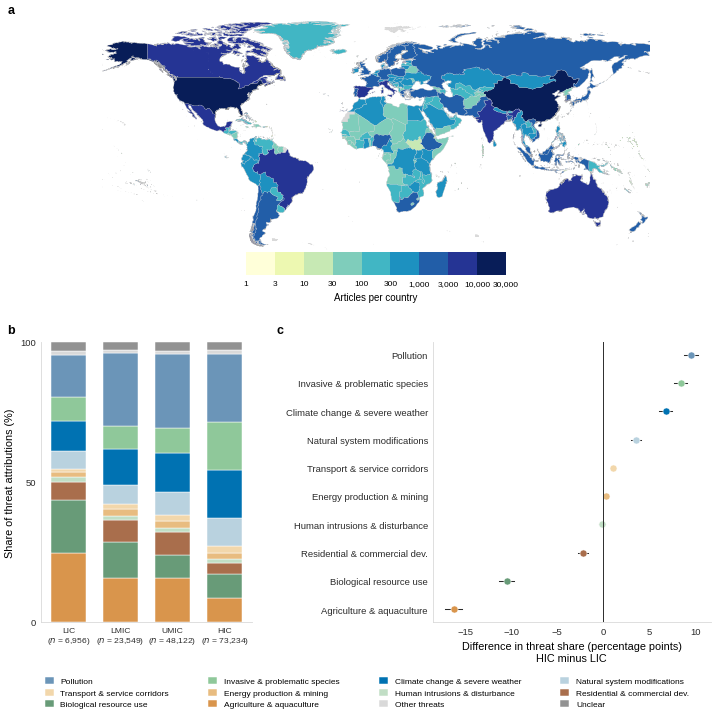

In [9]:
composition_figure = driver_composition.plot_income_composition(
    composition_analysis,
    income_groups=INCOME_GROUPS,
    threat_colors=THREAT_COLORS,
    threat_names=THREAT_DISPLAY_NAMES,
    country_counts=country_counts,
    polygons=country_polygons,
    contrast_excluded_threats=DRIVER_CONFIG["contrast_plot_excluded_threats"],
)
visualization.save_figure(
    composition_figure,
    FIGURE_DIR / DRIVER_CONFIG["composition_figure_filename"],
    formats=["pdf"],
    dpi=300,
    pad_inches=0.05,
)
plt.show()

## 5. Export

The two analytical tables for this result: within-group composition and the
extreme-group bootstrap contrast.

In [10]:
assert linked_country_df["UT"].nunique() == 146_630
assert figure_publication_count == 146_630
assert country_counts.shape[0] == 213
assert country_counts["record_count"].sum() == 165_174
assert evidence_preparation.country_exclusions["UT"].nunique() == 1_821
assert composition_analysis.group_counts["unique_publications"].tolist() == [
    6_956, 23_549, 48_122, 73_234
]
assert country_counts["record_count"].max() == 25_667
assert set(country_counts["iso3"]).issubset(
    set(country_polygons["ISO_3"].dropna())
)

In [11]:
written_paths = driver_composition.export_manuscript_tables(
    evidence_preparation,
    composition_analysis,
    data_directory=DATA_DIR,
    table_directory=TABLE_DIR,
    classified_assignments_file=DRIVER_CONFIG["classified_assignments_file"],
)
figure_paths = sorted(FIGURE_DIR.glob("*.pdf"))
for path in [*written_paths, *figure_paths]:
    print(path.relative_to(PROJECT_ROOT))

manifest = {
    "result": "02_income_composition",
    "method_details": {
        "analysis_scope": {
            "direction": DRIVER_CONFIG["direction"],
            "years": (
                f"{DRIVER_CONFIG['primary_start_year']}-"
                f"{DRIVER_CONFIG['primary_end_year']} complete publication years"
            ),
            "n_publications": int(figure_publication_count),
            "n_countries": int(len(country_counts)),
            "income_groups": list(INCOME_GROUPS),
            "n_threat_classes": int(len(observed_threat_order)),
        },
        "composition": {
            "grain": "UT x country x distinct threat",
            "income_assignment": (
                "World Bank income group matched to the publication year"
            ),
            "fractional_weight_formula": (
                "w_i,c,t = 1 / (number of countries_i x number of threats_i); "
                "weights sum to one per publication across all country-threat pairs"
            ),
            "group_publication_counts": {
                str(group): int(count) for group, count in group_sizes.items()
            },
        },
        "contrasts": {
            "extreme_group_comparison": "High income minus Low income, percentage points",
            "bootstrap_replicates": int(DRIVER_CONFIG["bootstrap_replicates"]),
            "bootstrap_seed": int(DRIVER_CONFIG["random_seed"]),
            "bootstrap_unit": (
                "publication; all country-resolved publications are resampled jointly"
            ),
        },
    },
    "artifacts": {
        "data/historical_income_publication_country_assignments.parquet": (
            "Publication-country assignments with historical income groups; "
            "the shared evidence base of this result and of results notebook 05."
        ),
        "csv/income_group_threat_composition.csv": (
            "Fractional threat composition within each historical income group."
        ),
        "csv/high_minus_low_income_bootstrap.csv": (
            "High-income minus low-income threat-share contrasts with bootstrap intervals."
        ),
        "figures/income_composition.pdf": (
            "Country coverage, income-group threat composition, and extreme-group contrast."
        ),
    },
}
manifest_path = OUTPUT_DIR / "manifest.json"
manifest_path.write_text(
    json.dumps(manifest, indent=2) + "\n", encoding="utf-8"
)
print(manifest_path.relative_to(PROJECT_ROOT))

notebooks/results/outputs/02_income_composition/data/historical_income_publication_country_assignments.parquet
notebooks/results/outputs/02_income_composition/csv/income_group_threat_composition.csv
notebooks/results/outputs/02_income_composition/csv/high_minus_low_income_bootstrap.csv
notebooks/results/outputs/02_income_composition/figures/income_composition.pdf
notebooks/results/outputs/02_income_composition/manifest.json
